# Can an acquisition branch on the frozen PFN reproduce every arm's ranking? Per-arm distillation

## Description

<!-- Written 2026-11-13 10:15 before the first run (pre-registration). Idea: research_log/decisions/0009 (Tim, 2026-11-13). Issue #13. -->

**Question.** Decision 0009 proposes an acquisition branch beside the frozen PFN: acquisition tokens at the observed locations read the PFN's train-context activations layer by layer, talk to each other, and are queried at candidate points. Before any policy is trained on it: **can this branch, reading only the train-context activations, reproduce the ranking of every arm (EI, PI, UCB, MES, mean) over candidates, well enough that maximizing its output is the same policy as the arm?** If yes, the backbone holds what all reference policies need, and policy improvement can start from them.

**Setup** (`experimental/acq_branch.py`, `tasks/acq_distill.py`, `analysis/acq_distill.py`). Frozen `pfn_large` (8 layers, width 256), fp32, noise-free prior tasks. One sweep member per input dimension: d = 1 (n_init 3, T = 15), d = 2 (4, 20), d = 4 (8, 40); contexts stay ≤ 48 points.
- *Branch.* 8 blocks, width 192, 4 heads; block b reads PFN layer b. Acquisition tokens start from the location only; a budget token (share used, share remaining, context size) joins their self-attention; query tokens start from the location and the budget. 5 output columns, one per arm. The PFN gets no gradient.
- *Training states.* 1500 prior tasks (split 4, offset 60000). Per task one full BO run per arm (deterministic arms, candidate seed 2) and 2 runs of uniformly random points; a state is a prefix of a run.
- *Teacher.* Each arm's acquisition value at the state's seed-0 candidate set (1024 Sobol points + 192 perturbations of the incumbent, the set the arms use in notebooks 12–15) and at 256 fresh queries (uniform, and perturbations of the incumbent and of observed points at scales 1e-3 to 0.3). MES's f\* samples come from the seed-0 set, so every query's value depends on the data and x only.
- *Loss.* Per arm, within the state: cross-entropy towards the arm's best candidate, plus a pairwise logistic loss on random pairs and on (arm's top 8, any) pairs. Only the order matters, so the arms' different scales play no role. 8000 steps of 48 states.
- *Evaluation* on 300 held-out tasks (offset 70000): runs of every arm under seed 0 and one random run per task, at every step.
  - `cand0`: the deployment candidate set (seed 0). `cand1`: a candidate set with unseen Sobol points (seed 1). `dense`: 1024 grid points (d ≤ 2) or Sobol points.
  - Per state and arm: does the branch pick the arm's best candidate (`top1`); what share of candidates the arm ranks above the branch's pick (`rank_pct`; a pick is *good* if ≤ 1%); Spearman over all candidates and over the arm's top quarter.
  - *Closed loop:* BO with the branch's column as the acquisition, against the arm itself, on the same tasks and candidates. Terminal log10 regret (ε = 1e-6), paired; share of runs that are identical step by step.
  - *Pictures* (d ≤ 2): the arm's score and the branch's score over the dense set for example states, to see artifacts.

**What to look for.**
1. d = 1 first: do the learned scores follow the arms over the whole domain, including between and at the observed points and at the incumbent?
2. Per arm and d: share of good picks on `cand0`, `cand1`, `dense`; does it hold on unseen query points?
3. Closed loop: is the regret of the distilled arm the same as the arm's?
4. Where it fails: by context size, by arm (PI and EI have large flat regions; MES depends on the candidate set through f\*).

**GO / NO-GO** (rule `analysis/acq_distill.py::distill_verdict`, per member).
- **GO**: for every arm, the branch's pick on `cand0` is good in ≥ 90% of states, and its closed-loop log10 regret is within 0.1 of the arm's. Next: the improvement step on this backbone (decision 0009 §2).
- **NO-GO**: for some arm, good picks in < 50% of states. Then the train-context activations as read here do not carry the arm; next: the `query_state` ablation (the branch also sees the PFN's query state) to tell an architecture problem from a training problem.
- **INCONCLUSIVE**: otherwise.

**Limits.**
- Distillation only: this shows that the branch can represent and learn the reference policies, not that it can improve on them.
- Agreement in ranking, not in value: the branch's scores are on an arbitrary scale.
- Ties: where an arm's values are tied over many candidates (PI or EI of 0), any of them counts as its best.
- Small picks differences can still change a run, since noise-free runs amplify them; hence the closed-loop check.
- pfn_large within its valid range (n ≤ 100, d ≤ 6).


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from anytime_acq.analysis import load_snapshot, show_header
from anytime_acq.analysis.acq_distill import distill_verdict

SNAPSHOT = "results/acq_distill/sanity_20261114-113335"  # set after `just snapshot`
snap = load_snapshot(SNAPSHOT)
show_header(snap)  # how it was run + configuration, generated from the snapshot

## How it was run

```bash
just sweep detached sanity experiment=acq_distill task.d=1 task.train.steps=12000 task.branch.post=2 task.branch.y_in=true task.branch.inc_token=true task.branch.aligned=true task.train.tasks.n_tasks=1000 task.eval.tasks.n_tasks=100 task.eval.n_closed_loop=100
```

|  |  |
|---|---|
| stage | sanity |
| sweep | `sanity_20261114-113335` |
| commit | `9c091abb2afb` (tag `sweep/acq_distill/sanity_20261114-113335`) |
| backend / host | detached / ulysses |
| ran | 2026-11-14T11:33:38 → 2026-11-14T12:23:07 |
| members | 1: 1 done |
| compute | 49.5 min wall, 0.0 min GPU |

## Configuration

Experiment config (`configs/experiment/acq_distill.yaml`):

```yaml
# @package _global_
# Can an acquisition branch on the frozen PFN reproduce every arm's ranking? Per-arm distillation (issue #13,
# decision 0009). Pre-registration: notebooks/16_2026-11-13_acq_distill.ipynb. One member per d (task.d=1,2,4).
defaults:
  - override /task: acq_distill

task:
  d: 2
```

**Varying:** nothing

**Replicates:** none

**Constant:**

```yaml
seed: 0
task:
  arms: '["ei", "pi0.01", "ucb0.995", "mes", "mean"]'
  branch.aligned: true
  branch.dropout: 0.0
  branch.ff_mult: 2
  branch.heads: 4
  branch.inc_token: true
  branch.post: 2
  branch.query_state: false
  branch.self_attn: true
  branch.width: 192
  branch.y_in: true
  candidates.local_sigmas: '[0.01, 0.05, 0.2]'
  candidates.n_local: 64
  candidates.n_sobol: 1024
  chunk: 64
  d: 1
  device: cuda
  eps: 1.0e-06
  eval.every: 1
  eval.n_closed_loop: 100
  eval.n_dense: 1024
  eval.n_examples: 3
  eval.n_random: 1
  eval.tasks.n_tasks: 100
  eval.tasks.split: 4
  eval.tasks.task_offset: 70000
  n_boot: 2000
  name: acq_distill
  pfn: pfn_large
  shape.d1: '[3, 15]'
  shape.d2: '[4, 20]'
  shape.d4: '[8, 40]'
  task_chunk: 300
  task_draw.n_dense: 16384
  task_draw.n_refine: 16
  task_draw.refine_steps: 200
  tf32: false
  train.batch: 48
  train.cand_seed: 2
  train.log_every: 100
  train.lr: 0.0003
  train.n_extra: 256
  train.n_queries: 512
  train.n_random: 2
  train.steps: 12000
  train.tasks.n_tasks: 1000
  train.tasks.split: 4
  train.tasks.task_offset: 60000
  train.warmup: 300
  train.weight_decay: 0.01
```

In [ ]:
runs = snap.runs
print("member status:", runs.status.value_counts().to_dict())
if not [c for c in runs.columns if c.endswith("task.d")]:
    runs = runs.assign(**{"task.d": int(snap.constants["task.d"])})  # one member: d is a constant of the sweep
dcol = [c for c in runs.columns if c.endswith("task.d")][0]
display(runs[[dcol, "status", "branch_params", "time/train_s", "time/evaluate_s"]].round(0))
def tab(name):
    t = snap.table(name)
    return t.merge(runs[["member", dcol]].rename(columns={dcol: "d"}), on="member") if "member" in t else t.assign(d=runs[dcol].iloc[0])
train, agree, closed, curves, summ = (tab(k) for k in ("train", "agree", "closed", "curves", "summary"))
ARMS = list(summ.arm.unique()); DS = sorted(agree.d.unique())

member status: {'DONE': 1}


,task.d,status,branch_params,time/train_s,time/evaluate_s
0,1,DONE,8047365.0,2832.0,137.0


## 1. Training

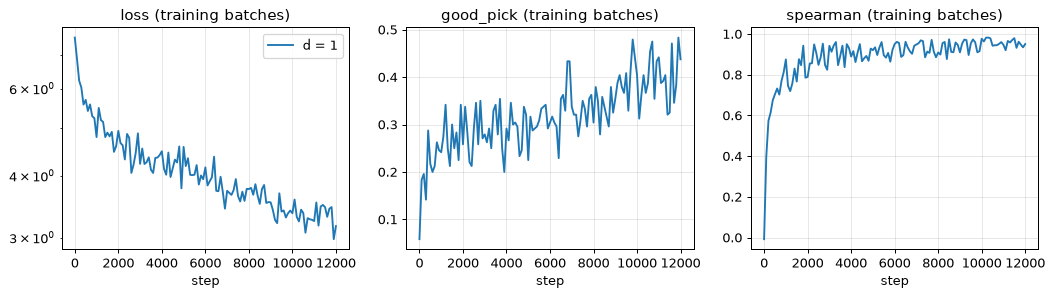

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.2), dpi=90)
for d, g in train.groupby("d"):
    for a, k in zip(ax, ("loss", "good_pick", "spearman")):
        a.plot(g.step, g[k], label=f"d = {d}"); a.set_title(k + " (training batches)"); a.set_xlabel("step"); a.grid(alpha=.3)
ax[0].set_yscale("log"); ax[0].legend(); plt.show()

## 2. Pictures: the arms and the learned scores over the whole domain (d = 1), and as maps (d = 2)

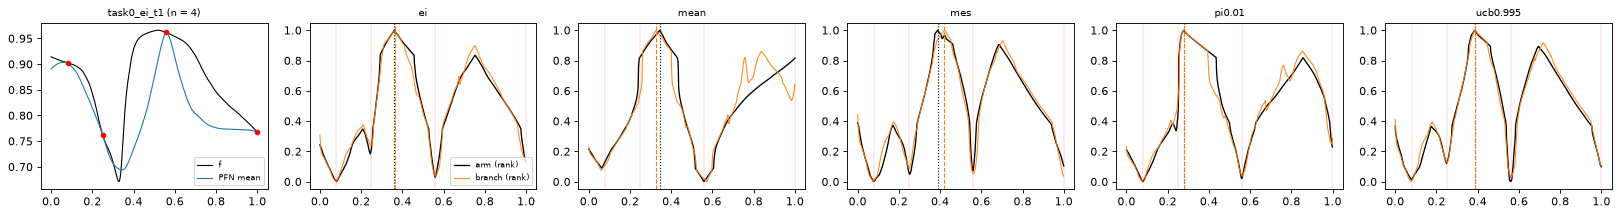

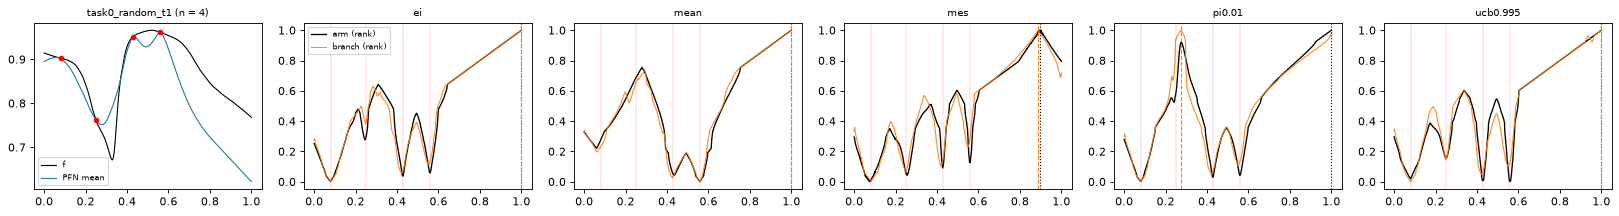

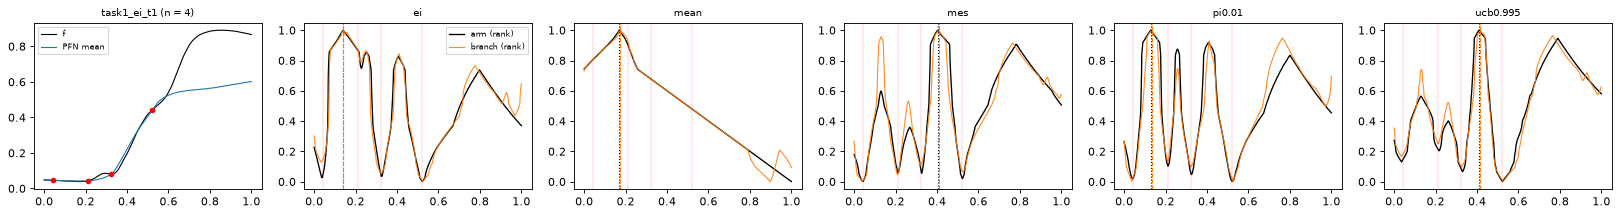

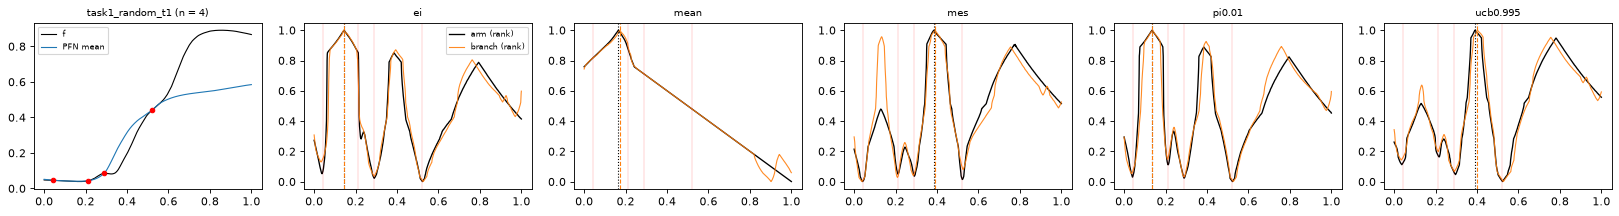

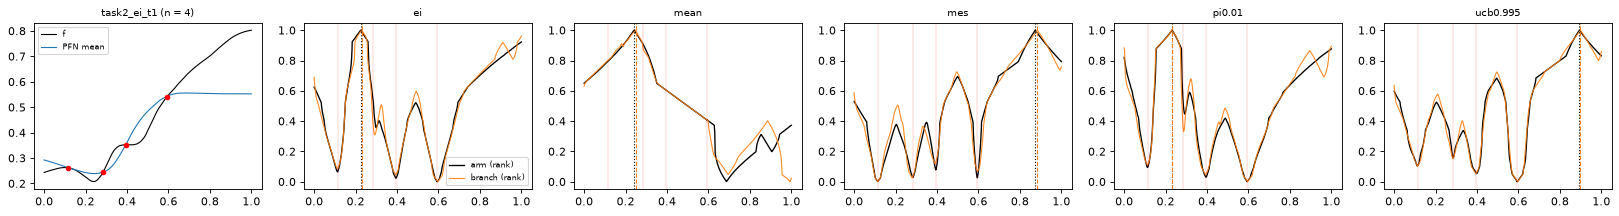

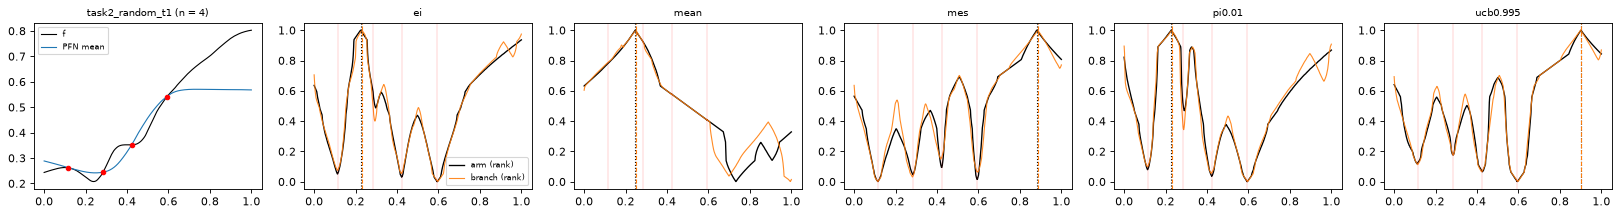

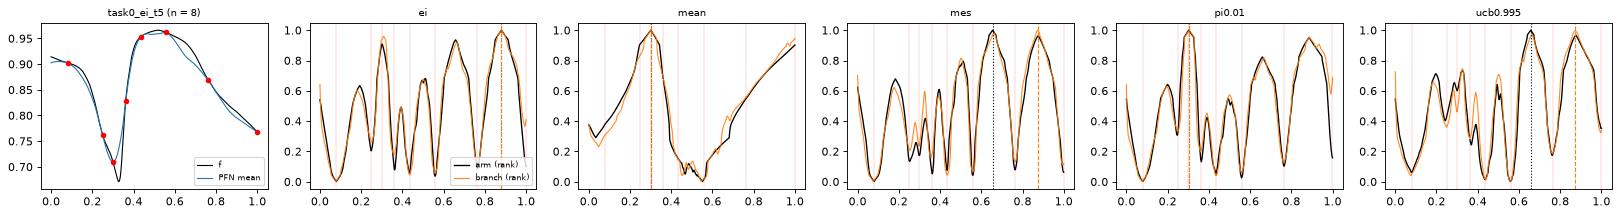

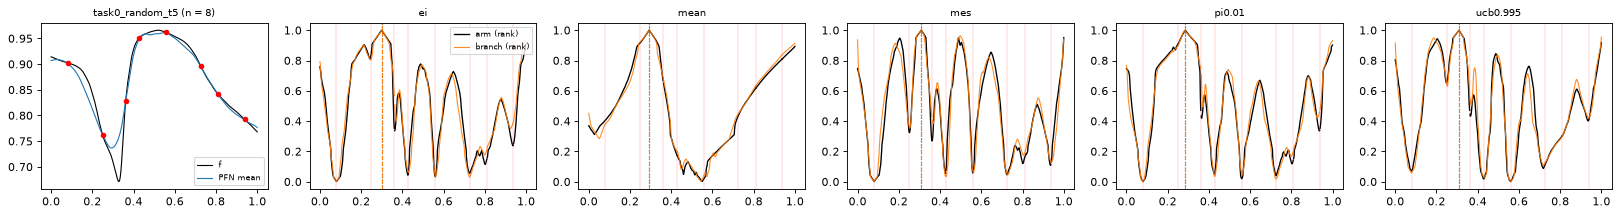

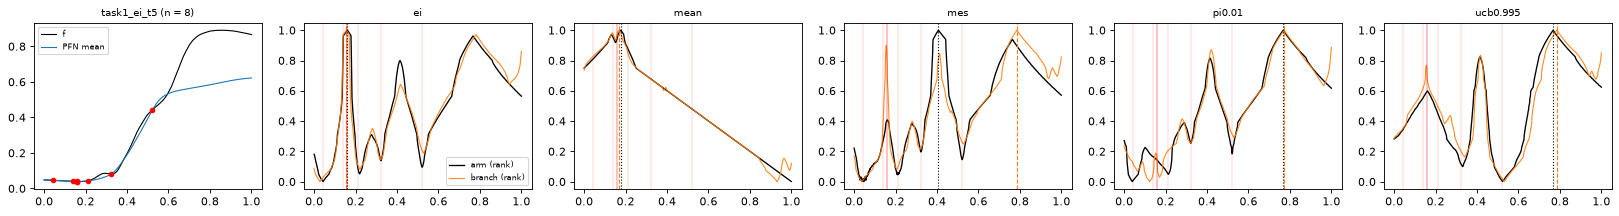

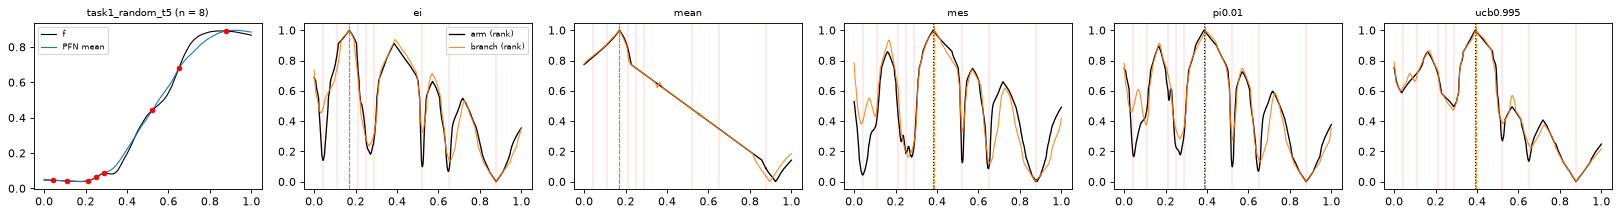

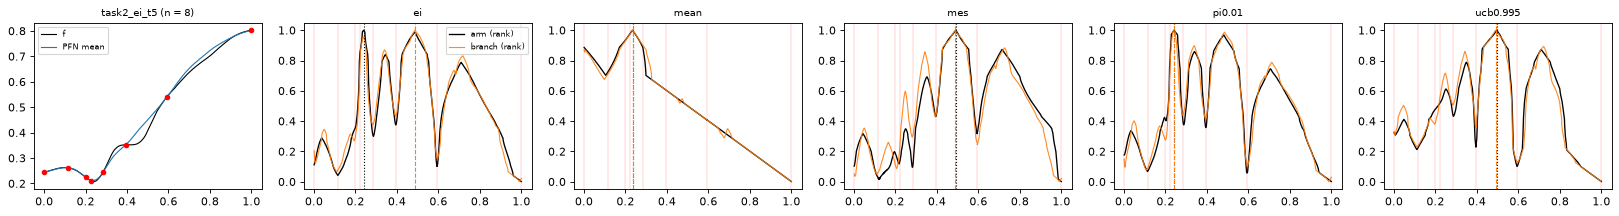

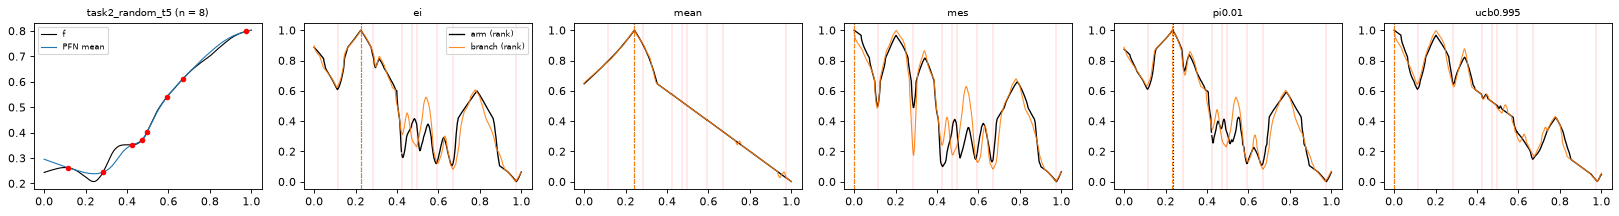

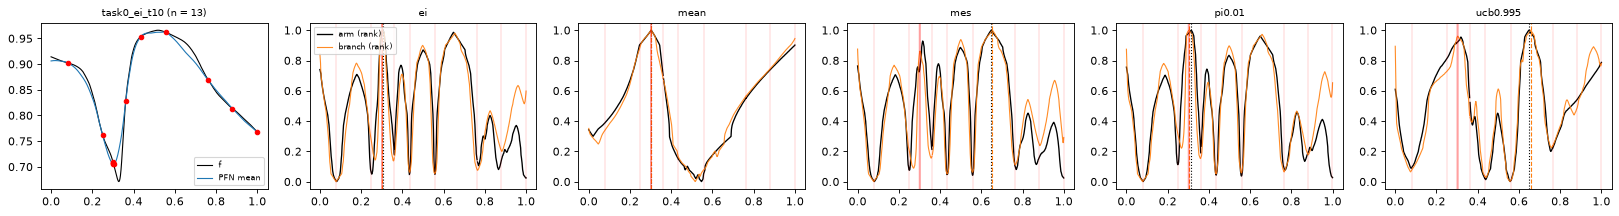

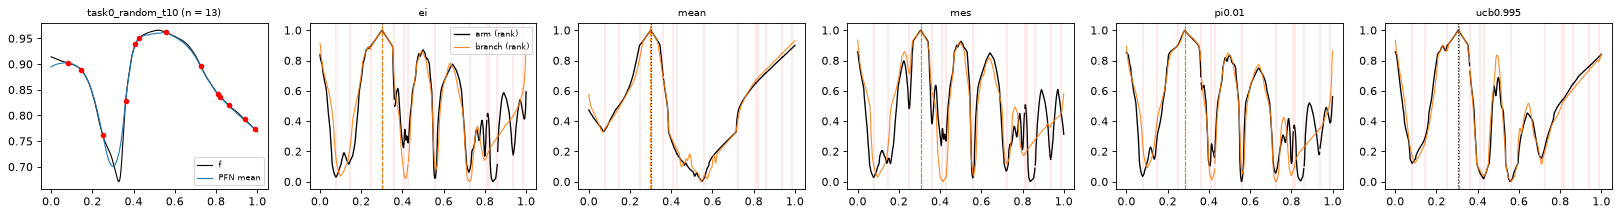

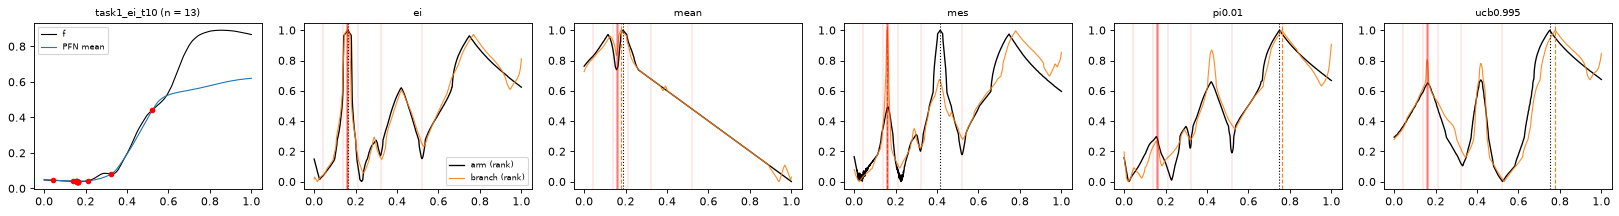

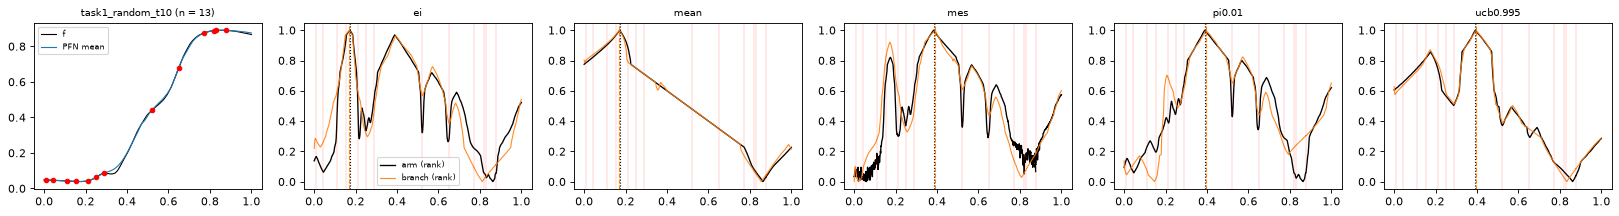

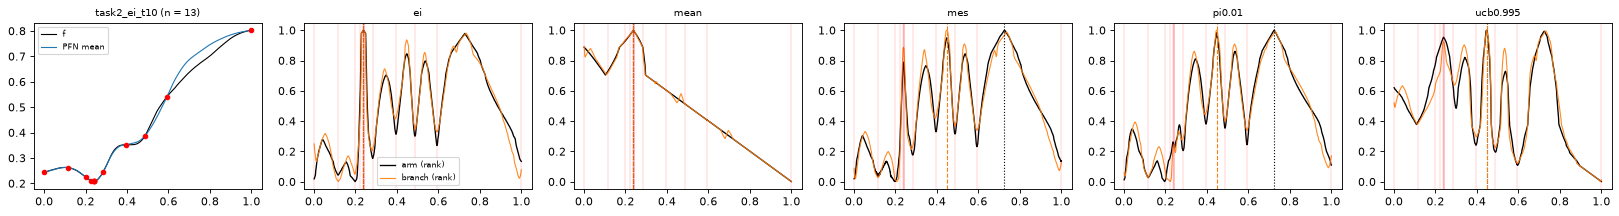

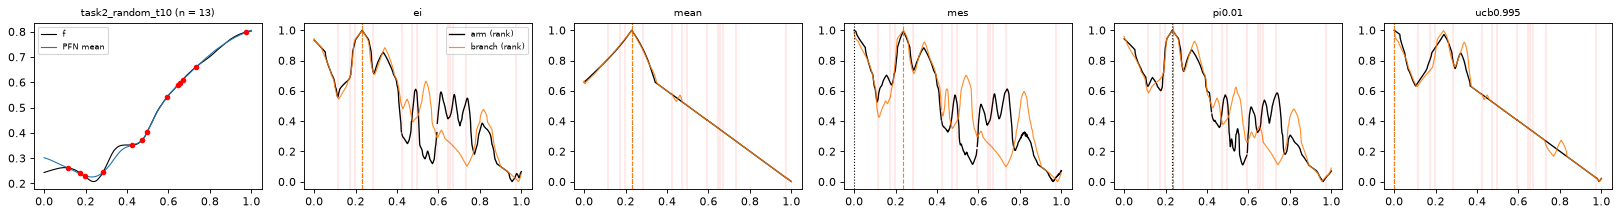

black: the arm's value as a rank over the grid (1 = best), dotted line = its argmax; orange: the branch, dashed = its argmax; red: observed points


In [ ]:
def rank01(v, valid):
    r = pd.Series(np.where(valid, v, np.nan)).rank(pct=True).to_numpy()
    return r
if 1 in DS:
    m = int(runs.loc[runs[dcol] == 1, "member"].iloc[0])
    ex, ctx = snap.table("examples"), snap.table("examples_ctx")
    ex, ctx = (t[t.member == m] if "member" in t else t for t in (ex, ctx))
    ids = [e for e in ex.example.unique() if e.startswith(("task0_", "task1_", "task2_"))]
    for eid in ids:
        g, c = ex[ex.example == eid].sort_values("x0"), ctx[ctx.example == eid]
        fig, ax = plt.subplots(1, len(ARMS) + 1, figsize=(3.4 * (len(ARMS) + 1), 2.8), dpi=80)
        ax[0].plot(g.x0, g.f, "k", lw=1, label="f"); ax[0].plot(g.x0, g.pfn_mean, "C0", lw=1, label="PFN mean"); ax[0].plot(c.x0, c.y, "ro", ms=4)
        ax[0].set_title(f"{eid} (n = {len(c)})", fontsize=9); ax[0].legend(fontsize=7)
        for a, arm in zip(ax[1:], ARMS):
            t, s, v = g[f"teacher:{arm}"].to_numpy(), g[f"student:{arm}"].to_numpy(), g.valid.to_numpy()
            a.plot(g.x0, rank01(t, v), "k", lw=1.2, label="arm (rank)"); a.plot(g.x0, rank01(s, v), "C1", lw=1, alpha=.9, label="branch (rank)")
            a.axvline(g.x0.to_numpy()[np.where(v, t, -np.inf).argmax()], color="k", ls=":", lw=1); a.axvline(g.x0.to_numpy()[np.where(v, s, -np.inf).argmax()], color="C1", ls="--", lw=1)
            for x in c.x0: a.axvline(x, color="r", lw=.3, alpha=.5)
            a.set_title(arm, fontsize=9)
        ax[1].legend(fontsize=7); plt.tight_layout(); plt.show()
    print("black: the arm's value as a rank over the grid (1 = best), dotted line = its argmax; orange: the branch, dashed = its argmax; red: observed points")

In [ ]:
if 2 in DS:
    m = int(runs.loc[runs[dcol] == 2, "member"].iloc[0])
    ex, ctx = snap.table("examples"), snap.table("examples_ctx")
    ex, ctx = (t[t.member == m] if "member" in t else t for t in (ex, ctx))
    for eid in [e for e in ex.example.unique() if e.startswith(("task0_ei", "task1_ei", "task0_random"))][:6]:
        g, c = ex[ex.example == eid], ctx[ctx.example == eid]
        k = int(round(np.sqrt(len(g))))
        fig, ax = plt.subplots(2, len(ARMS), figsize=(2.6 * len(ARMS), 5.2), dpi=80)
        for j, arm in enumerate(ARMS):
            for i, who in enumerate(("teacher", "student")):
                z = rank01(g[f"{who}:{arm}"].to_numpy(), g.valid.to_numpy()).reshape(k, k)
                ax[i, j].imshow(z.T, origin="lower", extent=(0, 1, 0, 1), cmap="viridis"); ax[i, j].plot(c.x0, c.x1, "r.", ms=3)
                ax[i, j].set_title(f"{'arm' if i == 0 else 'branch'}: {arm}", fontsize=8); ax[i, j].set_xticks([]); ax[i, j].set_yticks([])
        fig.suptitle(f"{eid} (n = {len(c)}), rank over the grid", fontsize=9); plt.tight_layout(); plt.show()

## 3. Agreement with the arms: candidate sets and the dense set

good: share of states where the arm ranks at most 1% of the candidates above the branch's pick


arm             ei   mean    mes  pi0.01  ucb0.995
d query_set                                       
1 cand0      0.633  0.626  0.540   0.506     0.549
  cand1      0.639  0.648  0.548   0.506     0.561
  dense      0.706  0.786  0.575   0.543     0.581

top1 (the arm's very best candidate):


arm             ei   mean    mes  pi0.01  ucb0.995
d query_set                                       
1 cand0      0.339  0.349  0.245   0.191     0.269
  cand1      0.346  0.366  0.258   0.188     0.277
  dense      0.375  0.410  0.265   0.196     0.288

Spearman over all candidates / over the arm's top quarter:


arm             ei   mean    mes  pi0.01  ucb0.995
d query_set                                       
1 cand0      0.937  0.981  0.910   0.885     0.967
  cand1      0.937  0.981  0.910   0.885     0.967
  dense      0.930  0.977  0.912   0.889     0.968

arm             ei   mean    mes  pi0.01  ucb0.995
d query_set                                       
1 cand0      0.824  0.916  0.775   0.752     0.825
  cand1      0.824  0.917  0.775   0.752     0.824
  dense      0.803  0.928  0.759   0.749     0.810

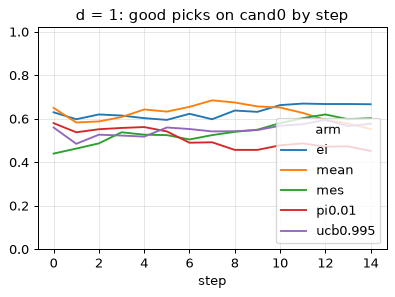

good picks on cand0 by the kind of run the state comes from:


run            ei   mean    mes  pi0.01  random  ucb0.995
d arm                                                    
1 ei        0.635  0.428  0.729   0.611   0.677     0.717
  mean      0.664  0.591  0.619   0.653   0.573     0.653
  mes       0.471  0.447  0.616   0.541   0.557     0.609
  pi0.01    0.509  0.417  0.533   0.445   0.573     0.558
  ucb0.995  0.511  0.469  0.586   0.545   0.592     0.593

In [ ]:
def wmean(g, col):
    return (g[col] * g.n_states).sum() / g.n_states.sum()
def table(col, by=("d", "query_set", "arm"), sel=agree):
    return sel.groupby(list(by)).apply(lambda g: wmean(g, col), include_groups=False).unstack(by[-1]).round(3)
print("good: share of states where the arm ranks at most 1% of the candidates above the branch's pick")
display(table("good")); print("top1 (the arm's very best candidate):"); display(table("top1"))
print("Spearman over all candidates / over the arm's top quarter:"); display(table("spearman")); display(table("spearman_top"))
fig, ax = plt.subplots(1, len(DS), figsize=(5 * len(DS), 3.2), dpi=90, squeeze=False)
c0 = agree[agree.query_set == "cand0"]
for a, d in zip(ax[0], DS):
    table("good", by=("step", "arm"), sel=c0[c0.d == d]).plot(ax=a); a.set_title(f"d = {d}: good picks on cand0 by step"); a.set_ylim(0, 1.02); a.grid(alpha=.3)
plt.show()
print("good picks on cand0 by the kind of run the state comes from:"); display(table("good", by=("d", "arm", "run"), sel=c0))

## 4. Closed loop: the branch's column as the acquisition, against the arm

cl:diff  cl:lo  cl:hi  cl:same_run  cl:same_steps
d arm                                                        
1 ei          0.315  0.164  0.479         0.01           0.60
  mean        0.128 -0.035  0.288         0.14           2.95
  mes         0.187  0.043  0.337         0.00           0.21
  pi0.01      0.119 -0.103  0.335         0.00           0.34
  ucb0.995    0.248  0.095  0.417         0.00           0.32

cl:diff = log10 terminal regret of the branch minus the arm's (positive = branch worse); same_run: share of runs identical step by step


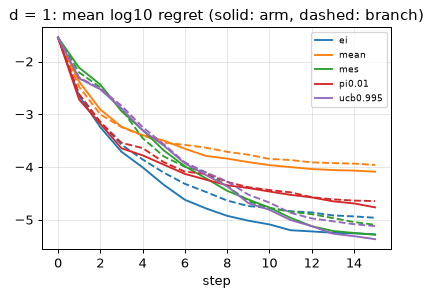

In [ ]:
display(summ.set_index(["d", "arm"])[["cl:diff", "cl:lo", "cl:hi", "cl:same_run", "cl:same_steps"]].round(3))
print("cl:diff = log10 terminal regret of the branch minus the arm's (positive = branch worse); same_run: share of runs identical step by step")
fig, ax = plt.subplots(1, len(DS), figsize=(5 * len(DS), 3.2), dpi=90, squeeze=False)
for a, d in zip(ax[0], DS):
    for i, arm in enumerate(ARMS):
        for pol, ls in (("teacher", "-"), ("student", "--")):
            g = curves[(curves.d == d) & (curves.arm == arm) & (curves.policy == pol)]
            a.plot(g.step, g.log_regret, ls, color=f"C{i}", label=arm if pol == "teacher" else None)
    a.set_title(f"d = {d}: mean log10 regret (solid: arm, dashed: branch)"); a.set_xlabel("step"); a.grid(alpha=.3); a.legend(fontsize=7)
plt.show()

## Observations (d = 1 only, 2026-11-14; snapshot `results/acq_distill/sanity_20261114-113335`)

One member: d = 1, 12000 training steps on 1000 tasks, branch with 2 post-readout blocks, y input, incumbent marker and aligned readout (the additions discussed with Tim on 2026-11-13); 100 evaluation tasks. Numbers from the cells above (`summary` table). The earlier 3000-step run without the additions was not snapshotted; from its run tables: Spearman 0.77–0.90, good picks 0.31–0.49, closed loop 0.5–0.7 log10 worse.

1. **The branch reproduces the shape of every arm over the whole domain.** Spearman over all candidates 0.89 (PI) to 0.98 (mean), the same on the second candidate set and on the dense grid. In the pictures (section 2) the learned curves follow the arms through every peak and dip, with no artifacts between the training points.
2. **It does not yet reproduce the picks.** The branch's pick is within the arm's top 1% in 51% (PI) to 63% (EI) of states; the arm's exact argmax in 19–35%. The misses are mostly near-ties: two peaks of almost equal height, and the branch takes the other one (e.g. MES and UCB in the second picture row).
3. **Closed loop the branch is worse than the arm it copies** by 0.12 to 0.32 log10 terminal regret (EI +0.315 [0.164, 0.479], UCB +0.248 [0.095, 0.417]; mean and PI not different from zero). Almost no run is identical step by step.
4. **Not converged.** The top-1 loss was still falling at step 12000 (3.19 at 10000, 2.98 at the end) and good picks on training batches rose from 0.30 to 0.44 over the last 4000 steps.
5. No difference between candidate set 0 (the teacher's f\* set for MES) and candidate set 1; the dense grid is slightly easier.

Limits: d = 1 only, one seed, 100 evaluation tasks; which of the four additions and the longer training made the difference is not separated.


## Verdict

**d = 1: INCONCLUSIVE** by the pre-registered rule (good picks on cand0 between 0.51 and 0.63 for every arm; GO needs 0.9, NO-GO is below 0.5). The ranking is learned, the argmax is not yet. This is a sanity-stage run; d = 2 and d = 4 were not run.


In [ ]:
for d, g in summ.groupby("d"):
    print(f"d = {d}: pre-registered rule: {distill_verdict(g)}; good picks on cand0 per arm:", dict(zip(g.arm, g["cand0:good_pick"].round(3))))

d = 1: pre-registered rule: INCONCLUSIVE; good picks on cand0 per arm: {'ei': 0.633, 'mean': 0.626, 'mes': 0.54, 'pi0.01': 0.506, 'ucb0.995': 0.549}
